# Greater Manchester Housing, Property & Council Tax Analysis

An exploratory analysis of house prices and housing stock across the 10 boroughs of Greater Manchester, using two official open datasets.

## What this notebook does

1. **Loads and filters** HM Land Registry and Valuation Office Agency (VOA) data to the 10 Greater Manchester boroughs.
2. **Cleans the data**: converts prices to numbers, keeps only standard residential sales, removes deleted or amended records, and standardises borough names.
3. **Summarises it** with medians rather than averages, so a few very expensive sales don't distort the picture.
4. **Visualises it** in six charts, each with a short note on what it shows and what it doesn't.

## Data sources
* **HM Land Registry, Price Paid Data (monthly update file):** individual property sales registered in the most recent monthly release.
* **Valuation Office Agency, Council Tax: Stock of Properties (CTSOP 1.0), 1993–2024:** number of homes in each council tax band, per local authority, at each annual snapshot.

## Limitations (read before the charts)
* The Price Paid file is a **monthly update**, not a complete record of all sales. It mainly contains sales that completed in the last year or so and were registered recently. Borough medians are a useful snapshot but are not official statistics. For a full picture, use the yearly Price Paid files or the UK House Price Index.
* The two datasets are analysed **side by side, not merged**. Council tax bands are based on 1991 valuations (in England), so they show the relative mix of housing, not current values.

---

In [1]:
# Imports
import glob
import os
import re
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

GM_BOROUGHS = ['Bolton', 'Bury', 'Manchester', 'Oldham', 'Rochdale',
               'Salford', 'Stockport', 'Tameside', 'Trafford', 'Wigan']

# Part 1: HM Land Registry, house prices

The Price Paid CSV has **no header row**, so the column names are supplied when loading (otherwise the first sale would be read as the header and lost).

In [2]:
PRICE_COLUMNS = [
    'transaction_id', 'price', 'transfer_date', 'postcode', 'property_type',
    'old_new', 'duration', 'paon', 'saon', 'street', 'locality',
    'town_city', 'district', 'county', 'ppd_category', 'record_status'
]

prices_df = pd.read_csv('pp-monthly-update-new-version.csv', header=None, names=PRICE_COLUMNS)
print(f"Rows in file (all of England & Wales): {len(prices_df):,}")

Rows in file (all of England & Wales): 90,867


In [3]:
def extract_gm_boroughs(df):
    # Keep only sales in the 10 Greater Manchester boroughs
    gm_upper = [b.upper() for b in GM_BOROUGHS]
    gm_df = df[df['district'].str.strip().str.upper().isin(gm_upper)].copy()
    print(f"Greater Manchester rows: {len(gm_df):,}")
    return gm_df


def clean_housing_data(df):
    # Cleans the raw price data and keeps only standard residential sales
    if df.empty:
        raise ValueError("This dataset has no records")

    df = df.copy()
    df['price'] = pd.to_numeric(df['price'], errors='coerce')
    df = df.dropna(subset=['price', 'district'])
    df = df[df['price'] > 0]

    # record_status: A = added, C = changed, D = deleted. Keep only 'A' so deleted records don't count.
    # ppd_category:  A = standard price paid, B = additional (repossessions, buy-to-let, company sales).
    before = len(df)
    df = df[(df['record_status'] == 'A') & (df['ppd_category'] == 'A')]
    print(f"Removed {before - len(df):,} changed/deleted or non-standard records; {len(df):,} remain")

    df['district'] = df['district'].str.strip().str.upper()
    df['date_dt'] = pd.to_datetime(df['transfer_date'])
    return df


def calculate_median_price(df):
    # Median sale price and number of sales per borough, most expensive first
    summary = (df.groupby('district')['price']
                 .agg(median_price='median', sales='count')
                 .reset_index()
                 .sort_values('median_price', ascending=False))
    return summary

In [4]:
gm_prices_df = extract_gm_boroughs(prices_df)
gm_prices_clean = clean_housing_data(gm_prices_df)
gm_medians = calculate_median_price(gm_prices_clean)

# Simple data checks
assert gm_medians['district'].nunique() == 10, "Expected all 10 boroughs"
assert (gm_prices_clean['price'] > 0).all()

print(gm_prices_clean['date_dt'].min().date(), "to", gm_prices_clean['date_dt'].max().date())
gm_medians

Greater Manchester rows: 4,068
Removed 1,104 changed/deleted or non-standard records; 2,964 remain
2015-10-03 to 2026-08-26


,district,median_price,sales
8,TRAFFORD,370000.0,299
6,STOCKPORT,325000.0,393
2,MANCHESTER,275000.0,451
1,BURY,247000.0,224
5,SALFORD,239995.0,267
3,OLDHAM,225000.0,213
7,TAMESIDE,220000.0,251
0,BOLTON,215000.0,291
4,ROCHDALE,210000.0,203
9,WIGAN,202000.0,372


### Chart 1: Median sale price by borough

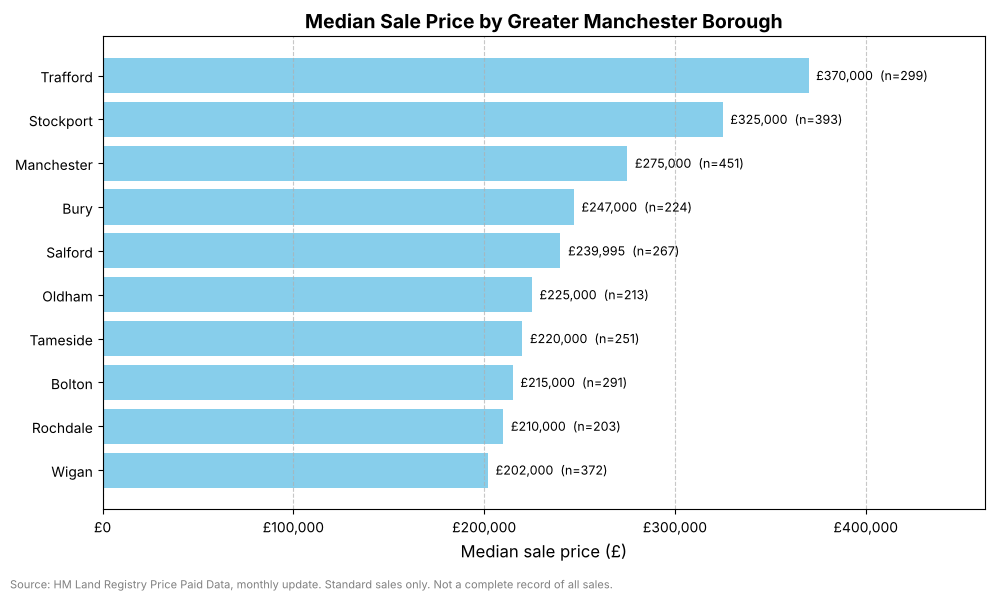

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))

# Sorted ascending so the most expensive borough ends up at the top of a horizontal bar chart
plot_df = gm_medians.sort_values('median_price', ascending=True)
bars = ax.barh(plot_df['district'].str.title(), plot_df['median_price'], color='skyblue')

ax.set_title('Median Sale Price by Greater Manchester Borough', fontsize=14, fontweight='bold')
ax.set_xlabel('Median sale price (£)', fontsize=12)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('£{x:,.0f}'))

# Label each bar with its median and number of sales
for bar, n in zip(bars, plot_df['sales']):
    width = bar.get_width()
    ax.text(width + 4000, bar.get_y() + bar.get_height() / 2,
            f'£{width:,.0f}  (n={n})', va='center', ha='left', fontsize=9)

ax.set_xlim(0, plot_df['median_price'].max() * 1.25)
ax.grid(axis='x', linestyle='--', alpha=0.7)
fig.text(0.01, 0.01, 'Source: HM Land Registry Price Paid Data, monthly update. Standard sales only. Not a complete record of all sales.',
         fontsize=8, color='grey')
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

### What this shows
* In this sample, **Trafford and Stockport** have the highest median sale prices and **Wigan, Rochdale and Bolton** the lowest.
* Each bar shows how many sales it is based on (n), so you can see how much data sits behind each median.

### What it doesn't show
* This is one monthly release of sales, not a full year, so the exact figures will differ from official house price statistics.
* Medians mix property types. A borough that sells more flats will have a lower median even if similar homes cost the same (see Chart 3).

### Chart 2: Recent monthly median price (and why there's no long-term trend)

An earlier version of this notebook fitted a curve to monthly prices back to 1995. But this file only holds **a handful of sales for most earlier months** (sometimes just one), so a long-term trend would mostly reflect which late-registered sales happen to be in the file, not the market.

This version only plots months with **at least 30 sales**, and shows the count next to the median so the reader can see how reliable each point is.

58 months in the file; 11 have at least 30 sales


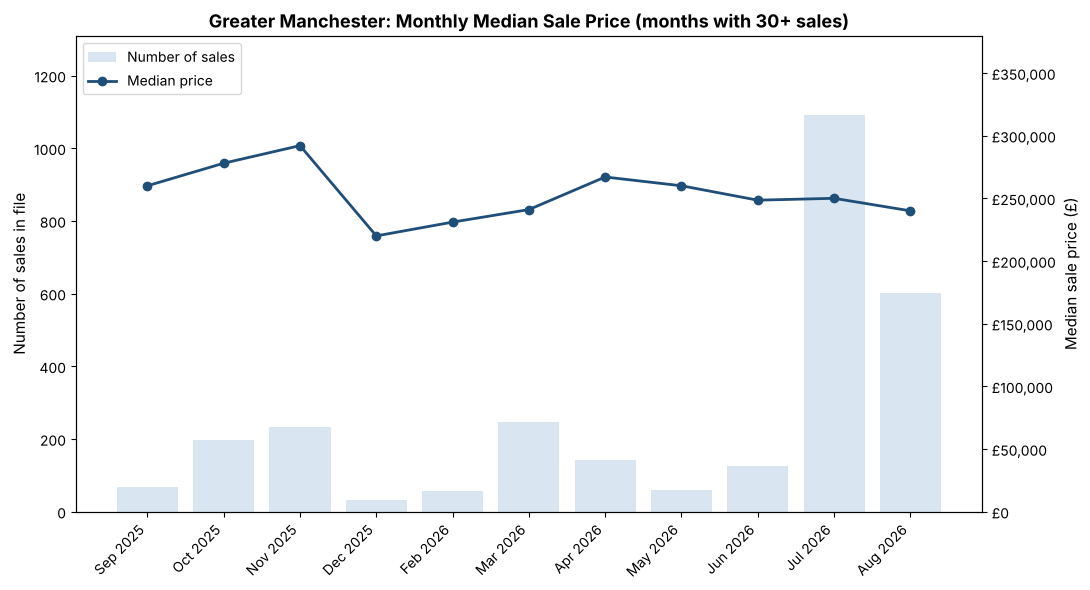

In [6]:
MIN_SALES = 30

monthly = (gm_prices_clean
           .assign(month=gm_prices_clean['date_dt'].dt.to_period('M'))
           .groupby('month')['price']
           .agg(median_price='median', sales='count')
           .reset_index())
monthly_reliable = monthly[monthly['sales'] >= MIN_SALES].copy()
monthly_reliable['month_label'] = monthly_reliable['month'].dt.strftime('%b %Y')

print(f"{len(monthly)} months in the file; {len(monthly_reliable)} have at least {MIN_SALES} sales")

fig, ax1 = plt.subplots(figsize=(11, 6))
x = np.arange(len(monthly_reliable))

ax1.bar(x, monthly_reliable['sales'], color='#d9e6f2', label='Number of sales')
ax1.set_ylabel('Number of sales in file', fontsize=11)
ax1.set_ylim(0, monthly_reliable['sales'].max() * 1.2)

ax2 = ax1.twinx()
ax2.plot(x, monthly_reliable['median_price'], color='#1f4e79', marker='o', linewidth=2, label='Median price')
ax2.set_ylabel('Median sale price (£)', fontsize=11)
ax2.yaxis.set_major_formatter(mtick.StrMethodFormatter('£{x:,.0f}'))
ax2.set_ylim(0, monthly_reliable['median_price'].max() * 1.3)

ax1.set_xticks(x)
ax1.set_xticklabels(monthly_reliable['month_label'], rotation=45, ha='right')
ax1.set_title(f'Greater Manchester: Monthly Median Sale Price (months with {MIN_SALES}+ sales)',
              fontsize=13, fontweight='bold')

lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(lines, labels, loc='upper left')
plt.tight_layout()
plt.show()

### What this shows
* For the months with enough data, the monthly median sale price across Greater Manchester stays between about £220,000 and £290,000.
* The bars show that most sales in this file completed in the last few months. That's a sign of how the monthly update works (recently registered sales), not a sudden rise in sales.

### What it doesn't show
* A long-term price trend. That needs the full yearly Price Paid files or the UK House Price Index, which is the next step for this project.

### What I learned
My first attempt fitted a degree-10 polynomial to monthly medians going back to 1995. It looked convincing, but most early months had only one or two sales, so the curve was fitting noise. Counting the sales behind each point made the problem obvious.

### Chart 3: Price ranges by property type

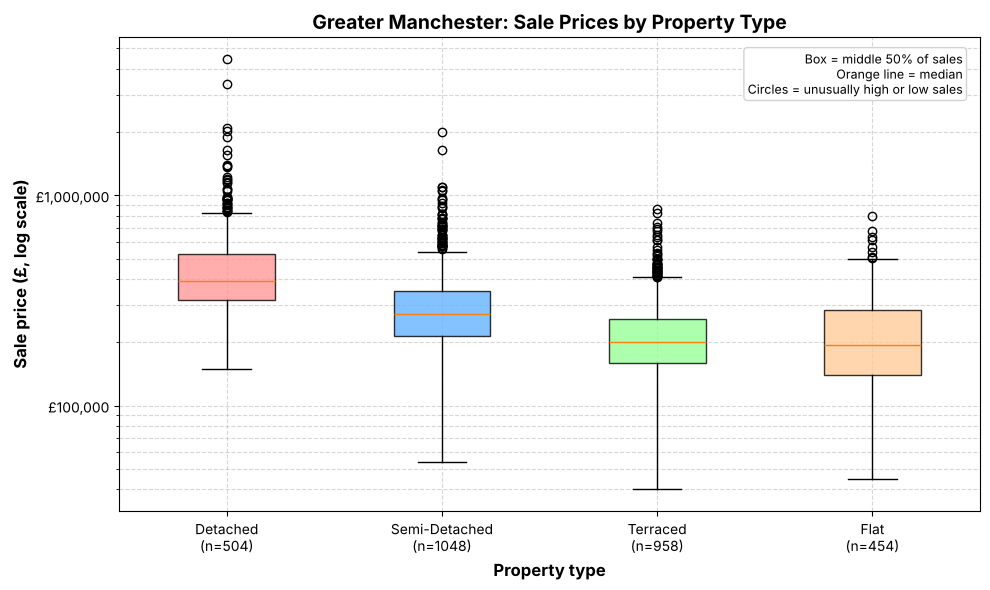

,type,sales,median_price
0,Detached,504,392500.0
1,Semi-Detached,1048,272500.0
2,Terraced,958,200000.0
3,Flat,454,195000.0


In [7]:
def property_price_type_distribution(df):
    # Map property type codes to readable names (O = other, excluded here)
    df = df.copy()
    df['type'] = df['property_type'].map({'D': 'Detached', 'S': 'Semi-Detached',
                                          'T': 'Terraced', 'F': 'Flat'})
    categories = ['Detached', 'Semi-Detached', 'Terraced', 'Flat']
    data = [df.loc[df['type'] == cat, 'price'] for cat in categories]
    counts = [len(d) for d in data]

    fig, ax = plt.subplots(figsize=(10, 6))
    bplot = ax.boxplot(data, tick_labels=[f'{c}\n(n={n})' for c, n in zip(categories, counts)],
                       patch_artist=True)

    colors = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99']
    for patch, color in zip(bplot['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.8)

    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('£{x:,.0f}'))
    ax.set_ylabel('Sale price (£, log scale)', fontsize=12, fontweight='bold')
    ax.set_xlabel('Property type', fontsize=12, fontweight='bold')
    ax.set_title('Greater Manchester: Sale Prices by Property Type', fontsize=14, fontweight='bold')

    # How to read a box plot, placed in a corner so it doesn't cover the data
    ax.text(0.98, 0.97, 'Box = middle 50% of sales\nOrange line = median\nCircles = unusually high or low sales',
            transform=ax.transAxes, ha='right', va='top', fontsize=9,
            bbox=dict(boxstyle='round', facecolor='white', edgecolor='lightgrey'))

    ax.grid(True, alpha=0.5, which='both', linestyle='--')
    plt.tight_layout()
    plt.show()

    return pd.DataFrame({'type': categories, 'sales': counts,
                         'median_price': [d.median() for d in data]})

property_price_type_distribution(gm_prices_clean)

### What this shows
* Detached homes have the highest median (about £392,500) and the most very high-priced sales. Terraced homes and flats have the lowest medians (about £200,000 and £195,000).
* The log scale keeps the very expensive sales visible without squashing everything else.

### What it doesn't show
* Size, condition or location within a borough, all of which also affect price.

# Part 2: Valuation Office Agency, housing stock and council tax bands

The VOA download is a zip of yearly snapshot CSVs (`CTSOP1_0_YYYY_MM_DD.csv`), plus one **combined file** with every year side by side (`CTSOP1_0_1993_2024_03_31.csv`).

In [8]:
# Extract the VOA zip (the file in this repo is named '...zip.zip')
zip_candidates = [f for f in ['CTSOP1-0-1993-2024.zip', 'CTSOP1-0-1993-2024.zip.zip'] if os.path.exists(f)]
VOA_DIR = 'voa_data'
with zipfile.ZipFile(zip_candidates[0], 'r') as zf:
    zf.extractall(VOA_DIR)

# Only the single-year snapshot files: CTSOP1_0_YYYY_MM_DD.csv
SNAPSHOT_PATTERN = re.compile(r'CTSOP1_0_(\d{4})_(\d{2})_(\d{2})\.csv$')
snapshot_files = sorted(f for f in glob.glob(os.path.join(VOA_DIR, 'CTSOP1_0_*.csv'))
                        if SNAPSHOT_PATTERN.search(os.path.basename(f)))
print(f"{len(snapshot_files)} yearly snapshot files found")


def load_gm_snapshot(path):
    # Load one VOA snapshot and keep the 10 GM boroughs, with numeric band columns
    df = pd.read_csv(path)
    df = df[df['area_name'].astype(str).str.strip().isin(GM_BOROUGHS)].copy()
    num_cols = [c for c in df.columns if c.startswith('band_') or c == 'all_properties']
    for col in num_cols:
        # '..' means not available in VOA files, so treat it as 0 here
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', ''), errors='coerce').fillna(0)
    return df


latest_file = snapshot_files[-1]
gm_voa_clean = load_gm_snapshot(latest_file)
assert len(gm_voa_clean) == 10, "Expected all 10 boroughs"
print(f"Latest snapshot: {os.path.basename(latest_file)}")
gm_voa_clean[['area_name', 'all_properties']].sort_values('all_properties', ascending=False)

32 yearly snapshot files found
Latest snapshot: CTSOP1_0_2024_03_31.csv


,area_name,all_properties
34,Manchester,249300
41,Wigan,152670
37,Salford,134060
38,Stockport,132950
32,Bolton,128140
39,Tameside,105280
40,Trafford,103950
35,Oldham,98790
36,Rochdale,97470
33,Bury,85100


## Chart 4: Number of homes per borough (2024)

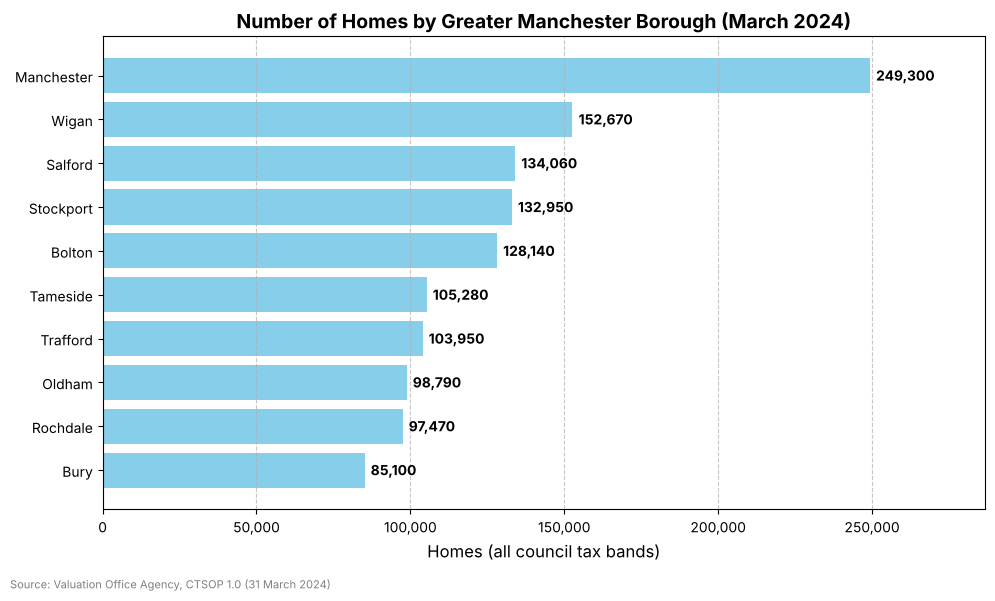

In [9]:
def voa_borough_housing_hierarchy(df):
    # Sorted ascending so the largest borough appears at the top of the horizontal bar chart
    sort_df = df.sort_values(by='all_properties', ascending=True)

    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.barh(sort_df['area_name'], sort_df['all_properties'], color='skyblue')

    ax.set_title('Number of Homes by Greater Manchester Borough (March 2024)', fontsize=14, fontweight='bold')
    ax.set_xlabel('Homes (all council tax bands)', fontsize=12)
    ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

    for bar in bars:
        width = bar.get_width()
        ax.text(width + 2000, bar.get_y() + bar.get_height() / 2, f'{width:,.0f}',
                va='center', ha='left', fontsize=10, fontweight='bold')

    ax.set_xlim(0, sort_df['all_properties'].max() * 1.15)
    ax.grid(axis='x', linestyle='--', alpha=0.7)
    fig.text(0.01, 0.01, 'Source: Valuation Office Agency, CTSOP 1.0 (31 March 2024)', fontsize=8, color='grey')
    plt.tight_layout(rect=(0, 0.03, 1, 1))
    plt.show()

voa_borough_housing_hierarchy(gm_voa_clean)

### What this shows
* **Manchester** has by far the most homes (about 249,000), followed by **Wigan** and **Salford**. **Bury** has the fewest (about 85,000).

### What it doesn't show
* Population or household size. More homes doesn't necessarily mean more people per home.

## Chart 5: Growth in the number of homes, 1993–2024

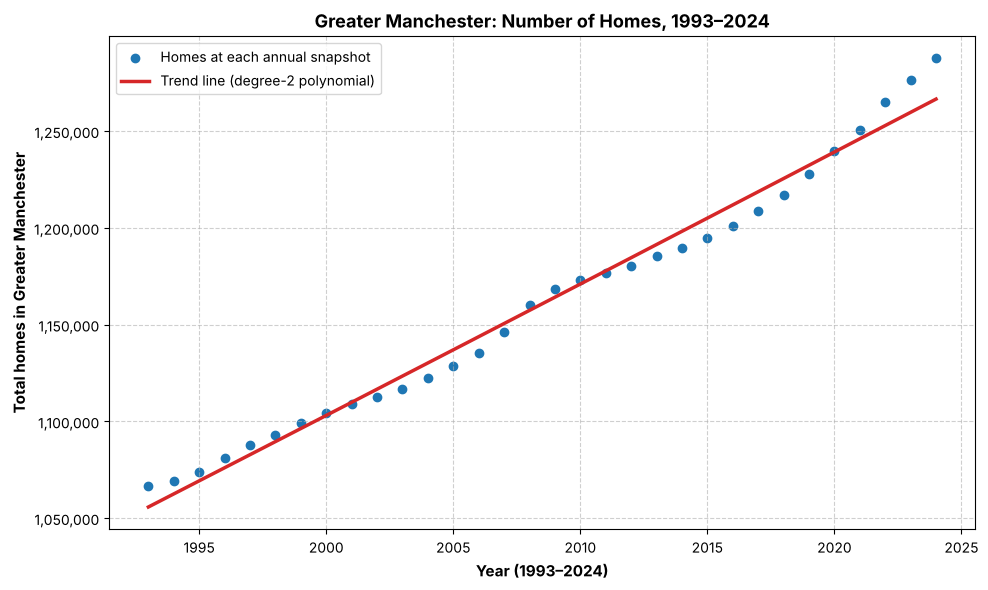

1993: 1,066,710 homes -> 2024: 1,287,710 homes (20.7% increase)


In [10]:
def voa_time_series_growth(files):
    rows = []
    for path in files:
        year = int(SNAPSHOT_PATTERN.search(os.path.basename(path)).group(1))
        snap = load_gm_snapshot(path)
        rows.append({'year': year, 'all_properties': snap['all_properties'].sum(), 'boroughs': len(snap)})

    growth = pd.DataFrame(rows).sort_values('year')
    assert (growth['boroughs'] == 10).all(), "Each snapshot should contain all 10 boroughs"

    x = growth[['year']]
    y = growth['all_properties']

    # A simple degree-2 trend line to summarise the overall shape
    poly = PolynomialFeatures(degree=2)
    model = LinearRegression().fit(poly.fit_transform(x), y)
    x_plot = pd.DataFrame({'year': np.linspace(x['year'].min(), x['year'].max(), 200)})
    y_plot = model.predict(poly.transform(x_plot))

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(x, y, color='#1f77b4', label='Homes at each annual snapshot')
    ax.plot(x_plot, y_plot, color='#d62728', linewidth=2.5, label='Trend line (degree-2 polynomial)')
    ax.set_xlabel(f"Year ({growth['year'].min()}–{growth['year'].max()})", fontsize=11, fontweight='bold')
    ax.set_ylabel('Total homes in Greater Manchester', fontsize=11, fontweight='bold')
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
    ax.set_title('Greater Manchester: Number of Homes, 1993–2024', fontsize=13, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.6, linestyle='--')
    plt.tight_layout()
    plt.show()

    first, last = growth.iloc[0], growth.iloc[-1]
    pct = (last['all_properties'] / first['all_properties'] - 1) * 100
    print(f"{int(first['year'])}: {first['all_properties']:,.0f} homes -> {int(last['year'])}: "
          f"{last['all_properties']:,.0f} homes ({pct:.1f}% increase)")
    return growth

voa_growth = voa_time_series_growth(snapshot_files)

### What this shows
* The number of homes in Greater Manchester grew steadily from about **1.07 million in 1993 to about 1.29 million in 2024**.
* The y-axis doesn't start at zero, which makes the change easier to see. In percentage terms it's roughly a 21% increase over 31 years.

### What I learned
An earlier version produced a huge outlier (about 75 million homes). The cause was a **combined all-years file** in the zip (`CTSOP1_0_1993_2024_03_31.csv`) that my file pattern also matched. It was read as "1993" and summed every column. My first fix dropped any year over 2.5 million homes, but that also removed the real 1993 snapshot. The proper fix was to match only the single-year file names, so all 32 snapshots are now included.

## Chart 6: Council tax band mix by borough (2024)

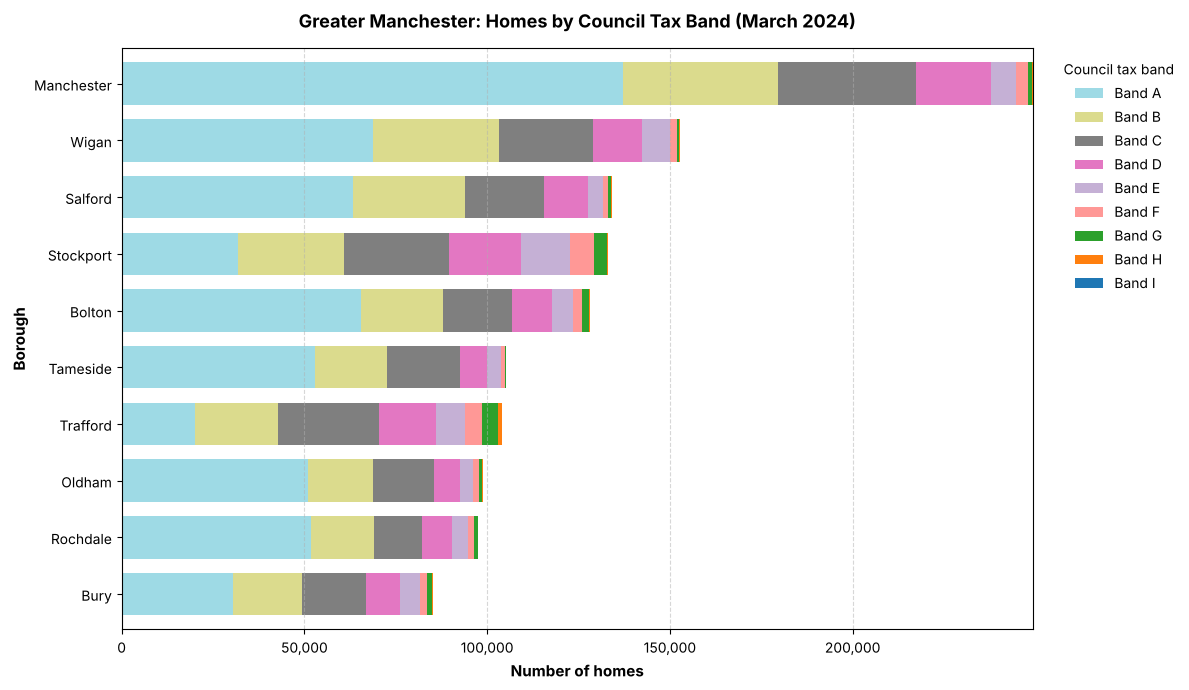

area_name
Manchester    55.0
Rochdale      53.1
Oldham        51.7
Bolton        51.0
Tameside      50.2
Salford       47.2
Wigan         45.1
Bury          35.9
Stockport     23.9
Trafford      19.2
Name: % of homes in Band A, dtype: float64

In [11]:
def voa_band_distribution_chart(df):
    band_cols = [c for c in df.columns if c.startswith('band_')]
    plot_df = df.set_index('area_name')[band_cols].copy()
    plot_df['total'] = plot_df.sum(axis=1)
    plot_df = plot_df.sort_values('total', ascending=True).drop(columns='total')
    plot_df.columns = ['Band ' + c.split('_')[1].upper() for c in band_cols]

    fig, ax = plt.subplots(figsize=(12, 7))
    plot_df.plot(kind='barh', stacked=True, ax=ax, colormap='tab20_r', edgecolor='none', width=0.75)

    ax.set_title('Greater Manchester: Homes by Council Tax Band (March 2024)', fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel('Number of homes', fontsize=11, fontweight='bold')
    ax.set_ylabel('Borough', fontsize=11, fontweight='bold')
    ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
    ax.legend(title='Council tax band', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
    ax.grid(True, axis='x', alpha=0.5, linestyle='--')
    plt.tight_layout()
    plt.show()

    # Share of homes in Band A, the lowest band
    share_a = (df.set_index('area_name')['band_a'] / df.set_index('area_name')['all_properties'] * 100)
    return share_a.sort_values(ascending=False).round(1).rename('% of homes in Band A')

voa_band_distribution_chart(gm_voa_clean)

### What this shows
* Boroughs differ a lot in their mix. Over half of Manchester's homes are in **Band A** (the lowest band), while Trafford and Stockport have far more homes in Bands C to E.
* Because council tax income depends on the band mix, boroughs with mostly Band A homes raise less council tax per home.

### What it doesn't show
* Current property values. Bands in England are based on 1991 valuations, so they show the relative mix of housing, not what homes are worth today.

---

## Next steps
* Replace the monthly update file with a full year of Price Paid Data, so borough medians are based on all sales.
* Combine the two datasets, for example comparing each borough's median price with its share of Band A homes.
* Add median earnings (ONS) to calculate an affordability ratio, house price divided by earnings, for each borough.